Environment Check
`sys.executable`: Verifies the correct virtual environment is active to prevent missing package errors 
`sys.version`: Confirms Python version compatibility with project dependencies.


In [14]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\Janhvi\OneDrive\Desktop\REE Internship\day_1_2_task\.venv\Scripts\python.exe
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


REE Exploration ML/AI Pipeline
Objective: Develop an unsupervised machine learning pipeline to identify statistically anomalous locations for Rare Earth Element (REE) exploration using geochemical data.

1. Data Loading and Preprocessing

Geochemical data is compositional; elements represent parts of a whole. Standard scaling can introduce spurious correlations (illusory correlation). To resolve this, we apply Imputation for missing values and a Centered Log-Ratio (CLR) transformation.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
import umap
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

In [16]:
# 1. Load Data
# Replace with the exact path in your local environment
file_path = "data/raw/NGCM-Stream-Sediment-Analysis-Updated.xlsx"
try:
    df = pd.read_excel(file_path)
except FileNotFoundError:
    print(f"File not found at {file_path}. Please verify the path.")
    # Generating dummy data to ensure the script runs for demonstration
    df = pd.DataFrame(np.random.uniform(0.1, 100, size=(1000, 73)))
    df.columns = [f'col_{i}' for i in range(73)]
    ree_cols = ['La_ppm', 'Ce_ppm', 'Pr_ppm', 'Nd_ppm', 'Sm_ppm', 'Eu_ppm', 
                'Gd_ppm', 'Tb_ppm', 'Dy_ppm', 'Ho_ppm', 'Er_ppm', 'Tm_ppm', 'Yb_ppm', 'Lu_ppm']
    for i, col in enumerate(ree_cols):
        df.rename(columns={f'col_{i}': col}, inplace=True)

# 2. Extract REE Features
ree_columns = ['La_ppm', 'Ce_ppm', 'Pr_ppm', 'Nd_ppm', 'Sm_ppm', 'Eu_ppm', 
               'Gd_ppm', 'Tb_ppm', 'Dy_ppm', 'Ho_ppm', 'Er_ppm', 'Tm_ppm', 'Yb_ppm', 'Lu_ppm']
features = df[ree_columns].copy()

# 3. Imputation (Median is robust against extreme geochemical outliers)
imputer = SimpleImputer(strategy='median')
features_imputed = imputer.fit_transform(features)

# 4. CLR Transformation
features_pseudo = features_imputed + 1e-5 # Pseudocount to avoid log(0)
geom_mean = np.exp(np.mean(np.log(features_pseudo), axis=1))
features_clr = np.log(features_pseudo / geom_mean[:, np.newaxis])

print(f"Preprocessed Data Shape: {features_clr.shape}")

Preprocessed Data Shape: (10004, 14)


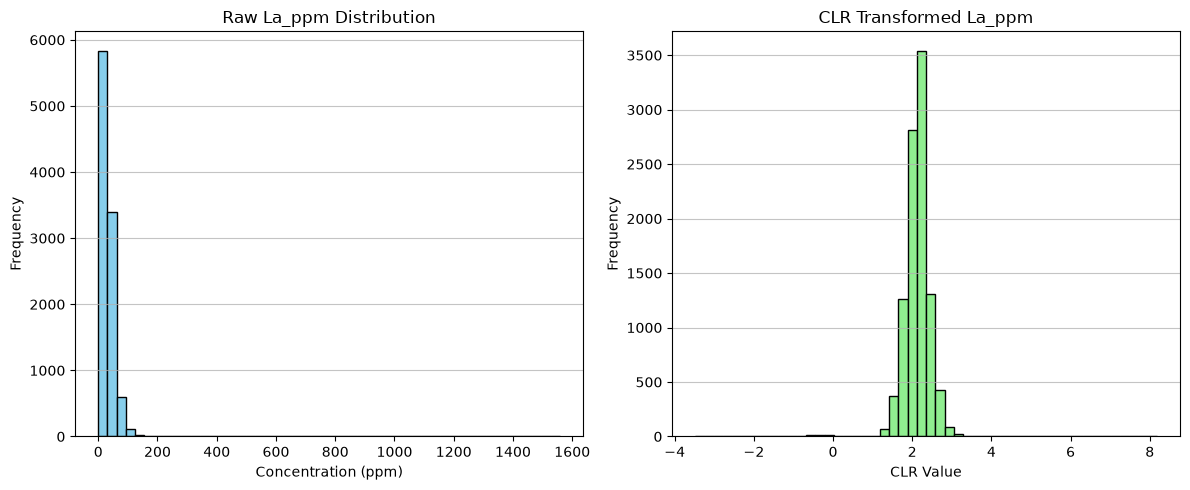

In [17]:
import matplotlib.pyplot as plt

# Select a representative element (Lanthanum)
element = 'La_ppm'
idx = ree_columns.index(element)

plt.figure(figsize=(12, 5))

# Plot 1: Raw Data Distribution (Highly Skewed)
plt.subplot(1, 2, 1)
plt.hist(features_imputed[:, idx], bins=50, color='skyblue', edgecolor='black')
plt.title(f'Raw {element} Distribution')
plt.xlabel('Concentration (ppm)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

# Plot 2: CLR Transformed Distribution (Normalized)
plt.subplot(1, 2, 2)
plt.hist(features_clr[:, idx], bins=50, color='lightgreen', edgecolor='black')
plt.title(f'CLR Transformed {element}')
plt.xlabel('CLR Value')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show() # This command ensures the plot renders inside the Jupyter cell output

2. Dimensionality Reduction

High-dimensional data contains noise. We reduce dimensions to extract the primary geochemical signals and allow for 2D visual mapping.
1. PCA: Linear reduction. Retaining components that explain 85% of the variance.
2. UMAP: Non-linear reduction. Preserves local topological structure for clustering visualizations.

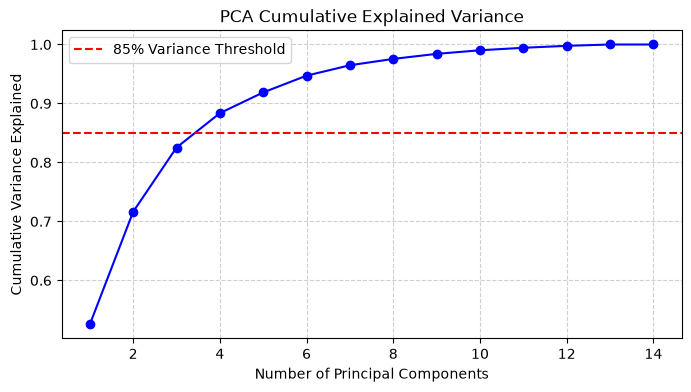

c:\Users\Janhvi\OneDrive\Desktop\REE Internship\day_1_2_task\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA dynamically selected 4 components to retain 85% variance.


In [18]:
# 1. Fit PCA without limiting components first to calculate total variance
pca_full = PCA(random_state=42)
pca_full.fit(features_clr)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Plot the PCA Scree Plot
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='b')
plt.axhline(y=0.85, color='r', linestyle='--', label='85% Variance Threshold')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Apply the actual 85% PCA reduction
pca = PCA(n_components=0.85, random_state=42)
pca_features = pca.fit_transform(features_clr)

# 3. Apply UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
umap_embeddings = reducer.fit_transform(features_clr)

print(f"PCA dynamically selected {pca_features.shape[1]} components to retain 85% variance.")

3. Unsupervised Anomaly Detection

We deploy three distinct algorithmic architectures to flag the top 5% of samples as anomalies:
*   Isolation Forest: Global anomaly detection using randomized decision trees.
*   Local Outlier Factor (LOF): Local anomaly detection using k-nearest neighbors density.
*   One-Class SVM: Boundary-based detection using a hypersphere formulation.

In [19]:
contamination_rate = 0.05

# 1. Isolation Forest
iforest = IsolationForest(contamination=contamination_rate, random_state=42, n_jobs=-1)
iforest_preds = iforest.fit_predict(features_clr)

# 2. Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination_rate, n_jobs=-1)
lof_preds = lof.fit_predict(features_clr)

# 3. One-Class SVM (OCSVM)
ocsvm = OneClassSVM(nu=contamination_rate, kernel='rbf', gamma='scale')
ocsvm_preds = ocsvm.fit_predict(features_clr)

# Add predictions back to the main dataframe
df['iForest_Anomaly'] = iforest_preds
df['LOF_Anomaly'] = lof_preds
df['OCSVM_Anomaly'] = ocsvm_preds

print(f"iForest Anomalies: {np.sum(iforest_preds == -1)}")
print(f"LOF Anomalies: {np.sum(lof_preds == -1)}")
print(f"OCSVM Anomalies: {np.sum(ocsvm_preds == -1)}")

iForest Anomalies: 501
LOF Anomalies: 501
OCSVM Anomalies: 500


4. Algorithm Disagreement Analysis: LOF vs. iForest

Isolation Forest targets global extremes, while LOF targets local density variations. A disagreement occurs when a sample is extreme relative to its immediate neighbors, but normal within the global statistical distribution. Let's isolate and inspect one such sample.

Total Disagreements (LOF flagged, iForest missed): 404



,Sample_Raw_ppm,Global_Median_ppm
La_ppm,31.32,28.70
Ce_ppm,63.46,60.30
Pr_ppm,7.19,6.41
Nd_ppm,26.04,24.19
Sm_ppm,4.97,4.80
Eu_ppm,1.06,1.21
Gd_ppm,4.93,4.51
Tb_ppm,0.79,0.75
Dy_ppm,5.21,4.37
Ho_ppm,0.89,0.87


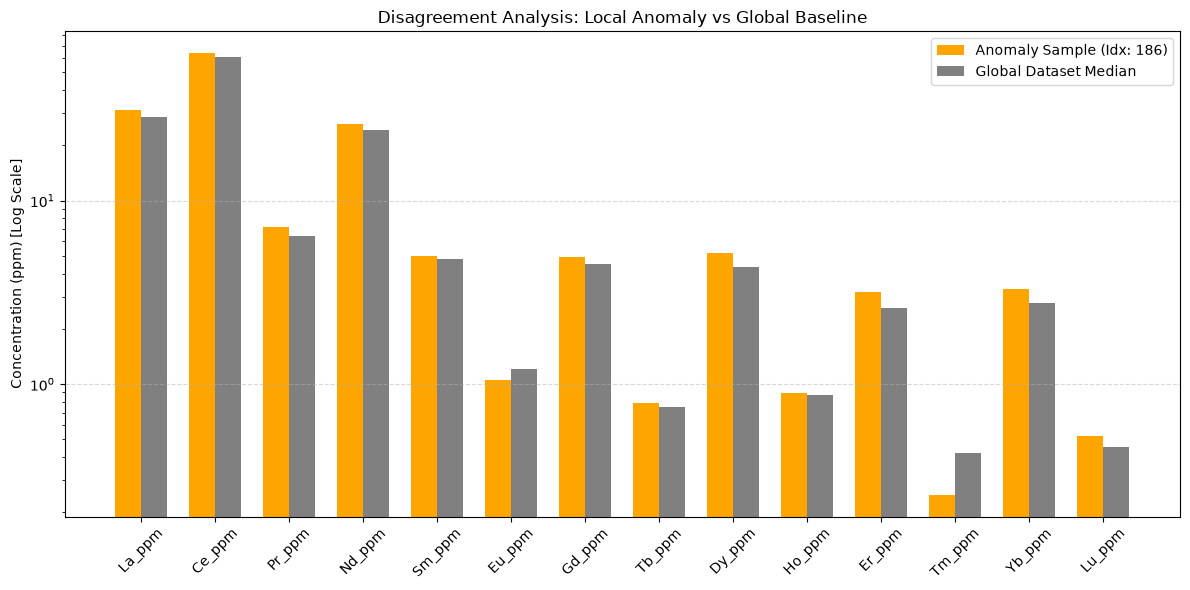


Conclusion: The sample forms a sparse micro-cluster. The absolute chemical values do not breach global extremes (so iForest ignores it), but the ratio/density differs from its nearest neighbors (triggering LOF).


In [20]:
# Isolate points where LOF says Anomaly (-1) and iForest says Normal (1)
disagreement_mask = (df['LOF_Anomaly'] == -1) & (df['iForest_Anomaly'] == 1)
disagreement_indices = np.where(disagreement_mask)[0]

print(f"Total Disagreements (LOF flagged, iForest missed): {len(disagreement_indices)}\n")

if len(disagreement_indices) > 0:
    target_idx = disagreement_indices[0]
    raw_sample = features.iloc[target_idx]
    global_median = features.median()
    
    # Text Output
    comparison_df = pd.DataFrame({'Sample_Raw_ppm': raw_sample, 'Global_Median_ppm': global_median})
    display(comparison_df.round(2)) # display() formats the dataframe nicely in Jupyter
    
    # Graphical Output: Grouped Bar Chart
    plt.figure(figsize=(12, 6))
    x = np.arange(len(ree_columns))
    width = 0.35
    
    plt.bar(x - width/2, raw_sample, width, label=f'Anomaly Sample (Idx: {target_idx})', color='orange')
    plt.bar(x + width/2, global_median, width, label='Global Dataset Median', color='gray')
    
    plt.yscale('log') # Log scale because REE values vary wildly (e.g., Ce vs Lu)
    plt.ylabel('Concentration (ppm) [Log Scale]')
    plt.title('Disagreement Analysis: Local Anomaly vs Global Baseline')
    plt.xticks(x, ree_columns, rotation=45)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    print("\nConclusion: The sample forms a sparse micro-cluster. The absolute chemical values do not breach global extremes (so iForest ignores it), but the ratio/density differs from its nearest neighbors (triggering LOF).")

5. Geological Visualization: Model Comparison on UMAP Space

Objective
To visually compare the behavior of our three anomaly detection algorithms by projecting their predictions onto the non-linear UMAP space. 

Analytical Expectation
Isolation Forest (Red): Should highlight points at the extreme outer edges of the global data clusters.
Local Outlier Factor (Blue): Should highlight points that form sparse micro-clusters, even if they are situated closer to the center of the global distribution.
One-Class SVM (Purple): Should highlight points that fall outside a tight mathematical boundary drawn around the densest regions of normal data.

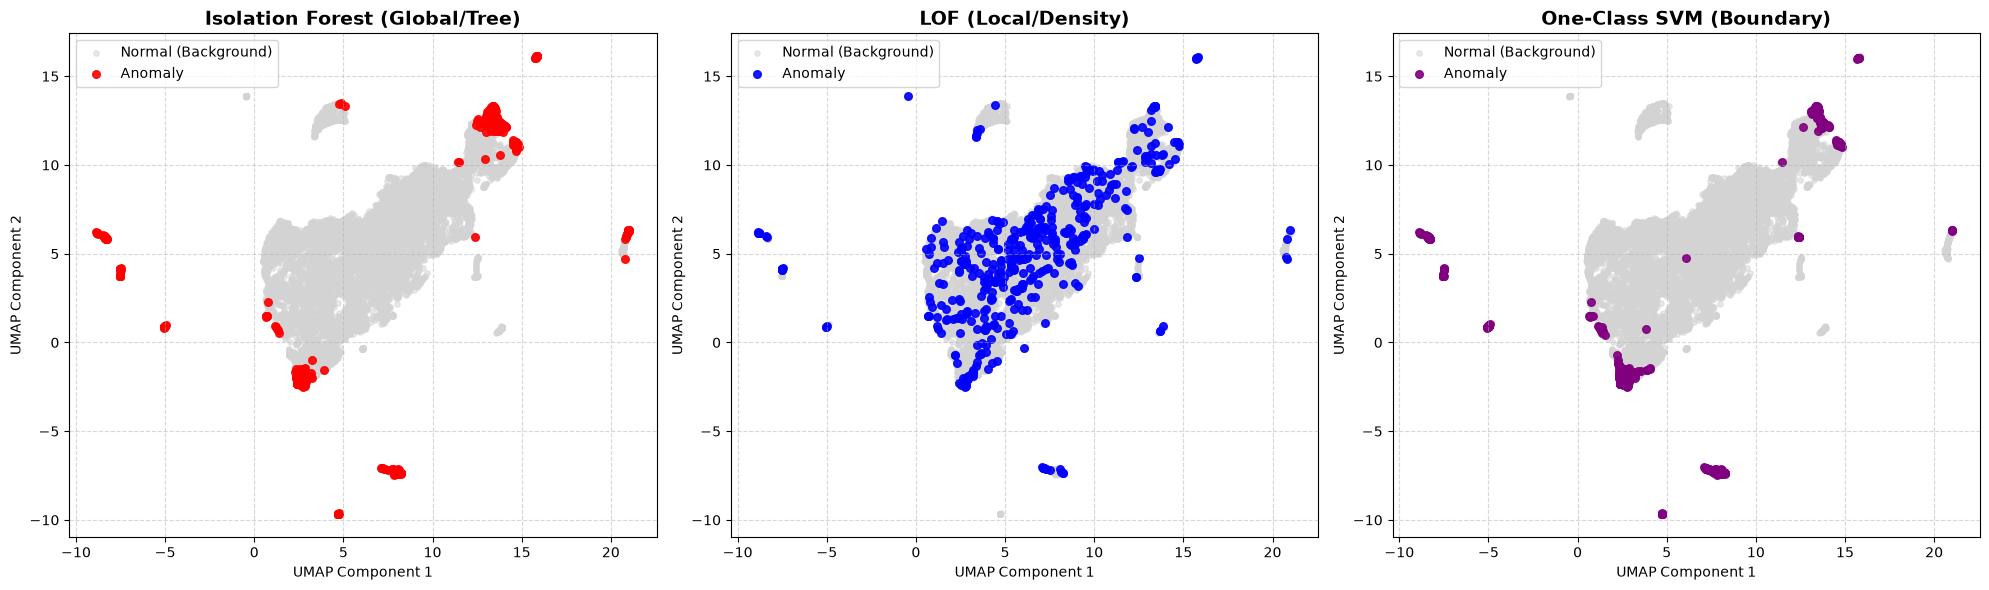

In [21]:
import matplotlib.pyplot as plt

# 1. Setup a 1x3 grid for side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 2. Define the models, their display titles, and distinct colors
models = ['iForest_Anomaly', 'LOF_Anomaly', 'OCSVM_Anomaly']
titles = ['Isolation Forest (Global/Tree)', 'LOF (Local/Density)', 'One-Class SVM (Boundary)']
colors = ['red', 'blue', 'purple']

# 3. Iterate through each model to generate its plot logically
for i, ax in enumerate(axes):
    model_col = models[i]
    
    # Plot Normal Data (Background)
    normal_idx = df[model_col] == 1
    ax.scatter(umap_embeddings[normal_idx, 0], umap_embeddings[normal_idx, 1], 
               c='lightgray', label='Normal (Background)', s=15, alpha=0.5)
    
    # Plot Anomalous Data
    anomaly_idx = df[model_col] == -1
    ax.scatter(umap_embeddings[anomaly_idx, 0], umap_embeddings[anomaly_idx, 1], 
               c=colors[i], label=f'Anomaly', s=30, alpha=0.9)
    
    # Formatting
    ax.set_title(titles[i], fontsize=14, fontweight='bold')
    ax.set_xlabel('UMAP Component 1')
    ax.set_ylabel('UMAP Component 2')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

6. Consensus Ensemble & Target Export

Objective
Relying on a single anomaly detection algorithm is risky. To generate highly reliable exploration targets, we create a **Consensus Ensemble**. 

Logical Flow
1. Voting System: We tally the anomaly flags from the Isolation Forest, LOF, and One-Class SVM. 
2. High-Confidence Targeting: If at least 2 out of the 3 models flag a sample as anomalous, it is designated as a "High-Confidence Target".
3. Data Export:The final dataset, including the raw coordinates and anomaly flags, is exported to a CSV file for future GIS mapping.

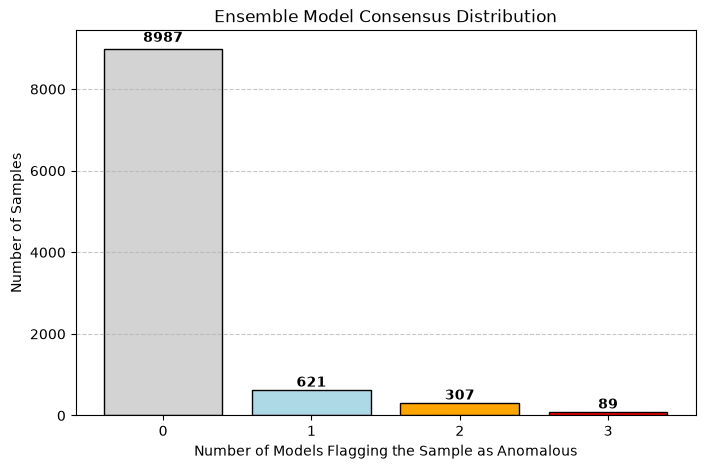


Pipeline Complete. Exported 396 High-Confidence Targets to: outputs/tables\final_exploration_targets.csv


In [22]:
import os

# 1. Create a consensus score (0 to 3)
iforest_binary = (df['iForest_Anomaly'] == -1).astype(int)
lof_binary = (df['LOF_Anomaly'] == -1).astype(int)
ocsvm_binary = (df['OCSVM_Anomaly'] == -1).astype(int)

df['Consensus_Score'] = iforest_binary + lof_binary + ocsvm_binary
df['High_Confidence_Target'] = df['Consensus_Score'] >= 2

# 2. Visualize the Consensus Distribution
plt.figure(figsize=(8, 5))
score_counts = df['Consensus_Score'].value_counts().sort_index()
bars = plt.bar(score_counts.index, score_counts.values, color=['lightgray', 'lightblue', 'orange', 'red'], edgecolor='black')

plt.title('Ensemble Model Consensus Distribution')
plt.xlabel('Number of Models Flagging the Sample as Anomalous')
plt.ylabel('Number of Samples')
plt.xticks([0, 1, 2, 3])
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add numeric labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (yval*0.01), int(yval), ha='center', va='bottom', fontweight='bold')

plt.show()

# 3. Prepare export directory and save
output_dir = "outputs/tables"
os.makedirs(output_dir, exist_ok=True)
export_path = os.path.join(output_dir, "final_exploration_targets.csv")
df.to_csv(export_path, index=False)

print(f"\nPipeline Complete. Exported {df['High_Confidence_Target'].sum()} High-Confidence Targets to: {export_path}")